#### **EDA**

k-means groups points by straight-line (Euclidean) distance, so anything that distorts distance can distort the clusters. These are the main things to check before fitting:

1. **Feature selection:** k-means clusters whatever it is given. Keep only features that describe what we want to cluster on, and remove IDs, labels and metadata. Wrong features give clusters that look fine statistically but mean nothing.

2. **Scale differences:** features with larger ranges dominate the distance. Standardize so each feature contributes comparably.

3. **Skew:** a few points end up many standard deviations out while the rest are packed together. Distance is squared, so those few dominate. Transform skewed features (e.g. Yeo-Johnson).

4. **Correlation:** highly correlated features count the same information twice, giving that theme extra weight. Check a correlation heatmap and drop one feature or use PCA.

In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns 

In [ ]:
import os
dir = "../data/" if os.path.exists("../data") else "data/"
data = pd.read_csv(dir + "spotify_tracks_clean.csv")

**1. Feature Selection**

In [17]:
# look at numeric data
numeric_data = data.select_dtypes('number')
numeric_data

# relevant features from numeric data include 9 features:
# - danceability 
# - energy 
# - loudness 
# - speechiness
# - acousticness 
# - instrumentalness 
# - liveness 
# - valence
# - tempo

relevant_features = ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']
features = numeric_data[relevant_features]

features

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,0.676,0.4610,-6.746,0.1430,0.0322,0.000001,0.3580,0.7150,87.917
1,0.420,0.1660,-17.235,0.0763,0.9240,0.000006,0.1010,0.2670,77.489
2,0.438,0.3590,-9.734,0.0557,0.2100,0.000000,0.1170,0.1200,76.332
3,0.266,0.0596,-18.515,0.0363,0.9050,0.000071,0.1320,0.1430,181.740
4,0.618,0.4430,-9.681,0.0526,0.4690,0.000000,0.0829,0.1670,119.949
...,...,...,...,...,...,...,...,...,...
89578,0.172,0.2350,-16.393,0.0422,0.6400,0.928000,0.0863,0.0339,125.995
89579,0.174,0.1170,-18.318,0.0401,0.9940,0.976000,0.1050,0.0350,85.239
89580,0.629,0.3290,-10.895,0.0420,0.8670,0.000000,0.0839,0.7430,132.378
89581,0.587,0.5060,-10.889,0.0297,0.3810,0.000000,0.2700,0.4130,135.960


**2. Scale Differences + Skew**

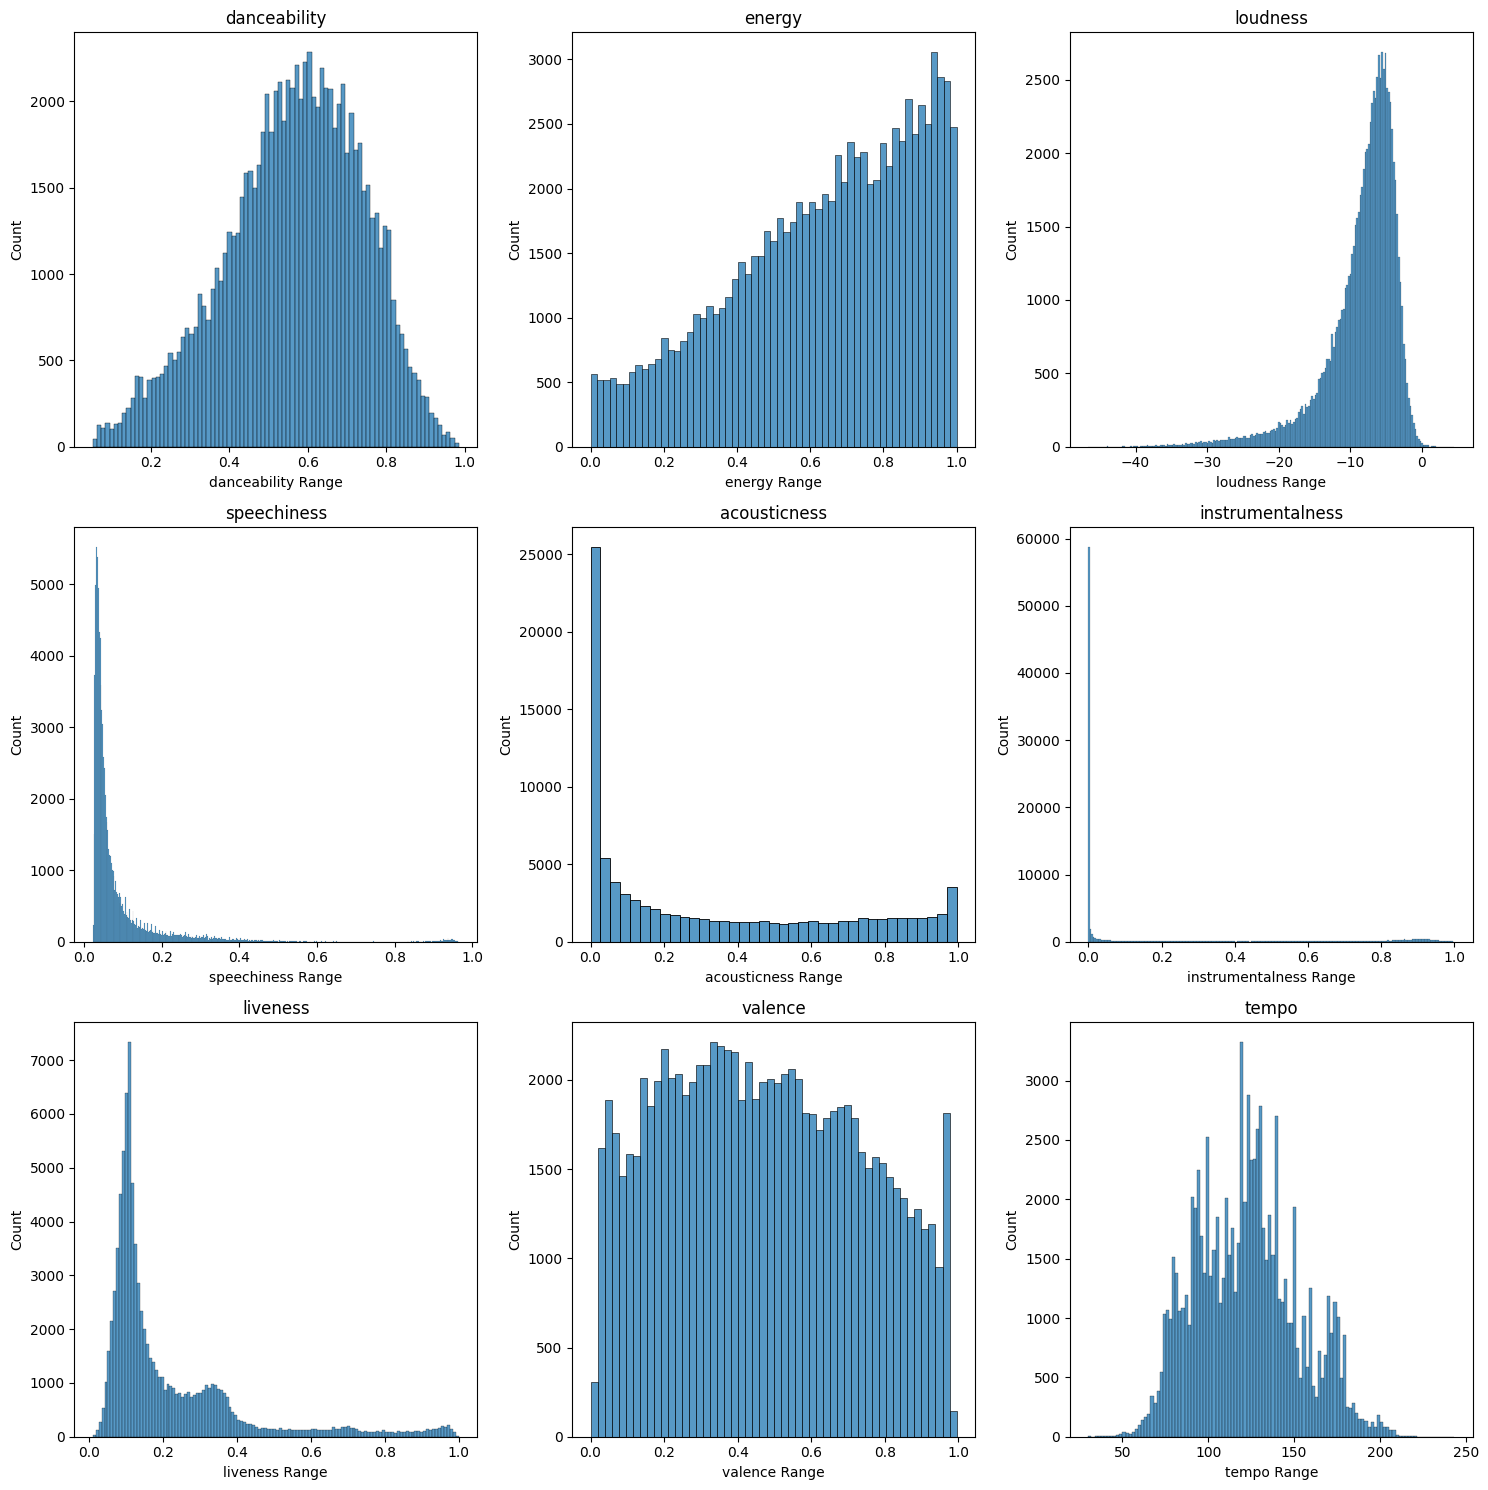

danceability mean: 0.5631515879128852, danceability std: 0.175271063639369
danceability skew: -0.36780707874591234
---------------------------------------
energy mean: 0.635354987340232, energy std: 0.255722091736194
energy skew: -0.5570139739931759
---------------------------------------
loudness mean: -8.47517025551723, loudness std: 5.179238181090929
loudness skew: -1.9392567089956292
---------------------------------------
speechiness mean: 0.08759558175100186, speechiness std: 0.11331768476483814
speechiness skew: 4.545728539724656
---------------------------------------
acousticness mean: 0.32798975002589775, acousticness std: 0.33811316376649664
acousticness skew: 0.6565749224876253
---------------------------------------
instrumentalness mean: 0.17257926992688344, instrumentalness std: 0.3231138992702481
instrumentalness skew: 1.570395294202227
---------------------------------------
liveness mean: 0.21655443454673315, liveness std: 0.1943422949487785
liveness skew: 2.066594766

In [ ]:
# analyse features 

fig, ax = plt.subplots(3, 3, figsize=(15, 15))

# flatten axis 
ax_flat = ax.flatten()

# plot histograms for the distribution of each feature
for i, feature in enumerate(relevant_features):
    sns.histplot(data=features, x=feature, ax=ax_flat[i])
    ax_flat[i].set_xlabel(f"{feature} Range")
    ax_flat[i].set_ylabel('Count')
    ax_flat[i].set_title(f"{feature}")

plt.tight_layout()
plt.show()

# different scales for each of our distributions -> feature scaling is required
# (PowerTransformer standardizes as well, so StandardScaler isn't needed)

# mean and std of the features
for feature in relevant_features:
    print(f"{feature} mean: {data[feature].mean()}, {feature} std: {data[feature].std()}")
    print(f'{feature} skew: {data[feature].skew()}')
    print('---------------------------------------')

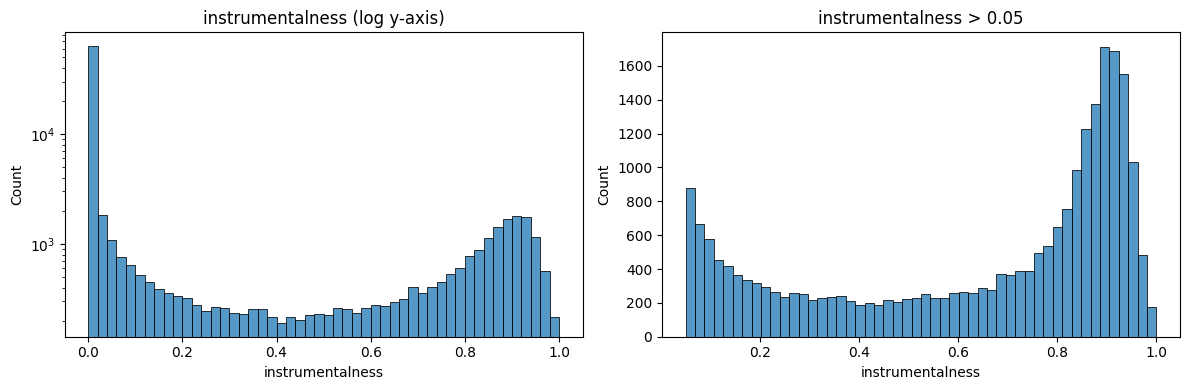

In [86]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(features['instrumentalness'], bins=50, ax=ax[0])
ax[0].set_yscale('log')
ax[0].set_title('instrumentalness (log y-axis)')

sns.histplot(features.loc[features['instrumentalness'] > 0.05, 'instrumentalness'], bins=50, ax=ax[1])
ax[1].set_title('instrumentalness > 0.05')

plt.tight_layout()
plt.show()

`speechiness`, `liveness` and `instrumentalness` are strongly right-skewed, and `loudness` is left-skewed.
`instrumentalness` is not a smooth tail: it is a huge spike at 0 (~59K tracks) plus a small bump around 0.8-0.95, so a transform won't fully fix it.

Skew matters for KMeans because a few points end up many standard deviations out while the rest are packed tightly together. Euclidean distance squares differences, so those few extreme points dominate the distance calculation and pull centroids toward them.

To reduce skew, we apply a **Yeo-Johnson power transform** (`PowerTransformer`). It applies a monotonic, non-linear transform (like a generalised log) that compresses the long tail and spreads out the crowded end, so the distribution becomes closer to symmetric. It also standardizes to mean 0 and std 1, so it replaces `StandardScaler`.

In [60]:
from sklearn.preprocessing import PowerTransformer
pt = PowerTransformer(method='yeo-johnson')  # standardize=True by default

smoothed_features = pd.DataFrame(pt.fit_transform(features), columns=features.columns)

smoothed_features

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,0.616715,-0.788587,0.176105,1.456865,-0.954272,-0.618394,1.241801,0.939852,-1.187681
1,-0.856317,-1.647086,-1.598367,0.478747,1.465378,-0.618316,-0.707309,-0.751864,-1.620584
2,-0.762322,-1.120485,-0.486248,-0.082637,-0.080096,-0.618411,-0.483760,-1.385761,-1.670533
3,-1.602435,-1.884168,-1.744055,-0.803581,1.443357,-0.617197,-0.293264,-1.283359,1.843859
4,0.257096,-0.849962,-0.476074,-0.183671,0.714106,-0.618411,-0.988654,-1.177837,-0.011013
...,...,...,...,...,...,...,...,...,...
89578,-2.007472,-1.473535,-1.497294,-0.560673,1.062252,1.861034,-0.933327,-1.780936,0.190837
89579,-1.999247,-1.760776,-1.722218,-0.644553,1.541698,1.865354,-0.649324,-1.775763,-1.296047
89580,0.324123,-1.210876,-0.698239,-0.568543,1.397503,-0.618411,-0.972258,1.036086,0.398246
89581,0.071150,-0.629784,-0.697194,-1.103586,0.488660,-0.618411,0.854840,-0.165320,0.512238


In [58]:
# Now evaluate mean, std, skew after smoothing
for feature in relevant_features:
    print(f'{feature} skew: {smoothed_features[feature].skew()}')
    print('---------------------------------------')

danceability skew: -0.04467111666534223
---------------------------------------
energy skew: -0.16449842676199383
---------------------------------------
loudness skew: 0.143527376760064
---------------------------------------
speechiness skew: 0.7215657499180607
---------------------------------------
acousticness skew: 0.22117045917478778
---------------------------------------
instrumentalness skew: 1.1606244331550881
---------------------------------------
liveness skew: 0.3773927850173391
---------------------------------------
valence skew: -0.024923641154061243
---------------------------------------
tempo skew: -0.016836601237560072
---------------------------------------


**Result:** the Yeo-Johnson transform substantially reduced skew.

| Feature | Skew before | Skew after |
| --- | --- | --- |
| `loudness` | -1.96 | 0.15 |
| `liveness` | 2.06 | 0.38 |
| `speechiness` | 4.55 | 0.69 |
| `instrumentalness` | 1.56 | 1.16 |

`loudness` and `liveness` are now close to symmetric, and `speechiness` is much improved but still slightly right-skewed. `instrumentalness` barely changed, because it is a spike at 0 with a small high bump rather than a long tail, so a power transform can't fix it.

**3. Correlation**

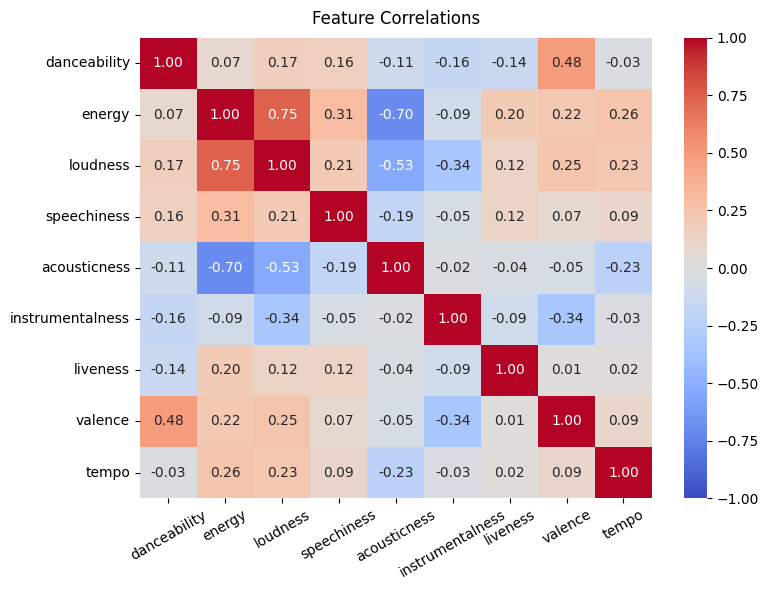

In [81]:
corr = smoothed_features.corr() # create the correlation matrix between the variables 

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, center=0)
plt.tick_params(axis='x', rotation=30)
plt.title('Feature Correlations', pad=10)

plt.tight_layout()
plt.show()

Looking at the correlation heatmap, the strongest correlations (by absolute value) are:
- `(loudness, energy)`: **0.75**
- `(acousticness, energy)`: **-0.70**
- `(acousticness, loudness)`: **-0.53**
- `(valence, danceability)`: **0.48**

`loudness`, `energy` and `acousticness` share an "intensity" theme (loud and energetic tracks tend to be non-acoustic). In k-means this theme would effectively be counted three times, weighting it more heavily than other features. We will test combining them into a single component using PCA.

`valence` and `danceability` (0.48) share under a quarter of their variance (r² ≈ 0.23), so they are mostly independent signals and will be left as they are.

In [85]:
from sklearn.decomposition import PCA

group = ['energy', 'loudness', 'acousticness'] # group these into a single variable via PCA

pca_group = PCA(n_components=1) # how many components to group into (1)
intensity = pca_group.fit_transform(smoothed_features[group]) # group energy, loudness, acousticness into a single feature

print(pca_group.explained_variance_ratio_) # how much of the 3 features PC1 keeps - degree of correlation between all 3 variables
                                           # 0.7755 -> the three features are fairly strongly correlated: 
                                           # PC1 keeps ~77.6% of their combined variance and discards ~22.4%
                                           # combined variance = total spread of the 3 features added together, keeping 100% indicates perfect correlation

print(dict(zip(group, pca_group.components_[0].round(2)))) # weighted contribution of each feature to the combined intensity feature

# swap the 3 columns for the 1 combined feature "intensity"
grouped = smoothed_features.drop(columns=group).copy()
grouped['intensity'] = intensity

grouped

[0.77551884]
{'energy': np.float64(0.61), 'loudness': np.float64(0.57), 'acousticness': np.float64(-0.55)}


,danceability,speechiness,instrumentalness,liveness,valence,tempo,intensity
0,0.616715,1.456865,-0.618394,1.241801,0.939852,-1.187681,0.143452
1,-0.856317,0.478747,-0.618316,-0.707309,-0.751864,-1.620584,-2.722198
2,-0.762322,-0.082637,-0.618411,-0.483760,-1.385761,-1.670533,-0.917217
3,-1.602435,-0.803581,-0.617197,-0.293264,-1.283359,1.843859,-2.937742
4,0.257096,-0.183671,-0.618411,-0.988654,-1.177837,-0.011013,-1.183823
...,...,...,...,...,...,...,...
89578,-2.007472,-0.560673,1.861034,-0.933327,-1.780936,0.190837,-2.336403
89579,-1.999247,-0.644553,1.865354,-0.649324,-1.775763,-1.296047,-2.904075
89580,0.324123,-0.568543,-0.618411,-0.972258,1.036086,0.398246,-1.907475
89581,0.071150,-1.103586,-0.618411,0.854840,-0.165320,0.512238,-1.050143


**Decisions carried into the pipeline**

- **Scaling and skew:** Yeo-Johnson (`PowerTransformer`) on the 9 features. It standardizes too, so no separate `StandardScaler`.
- **`instrumentalness`:** still skewed after the transform (~1.16) because it is a spike at 0 with a small high bump. Handling is still to be decided (binary flag `> 0.5` or keep as is).
- **Correlation:** `energy`, `loudness` and `acousticness` share an "intensity" theme (|r| of 0.53-0.75). Candidate: combine them with PCA into one `intensity` component (PC1 keeps ~77.6% of their variance). **To test during modelling:** cluster with all 9 features vs with `intensity`, and compare the personas.
- **`valence` and `danceability`** (r = 0.48) are mostly independent, so they stay as they are.